In [1]:
!pip install shap

In [2]:
#Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn import metrics

In [3]:
# carrega os valores nas unidades reais (anos, IMC, pressão...)
data = load_diabetes(as_frame=True, scaled=False)
df = data.frame

# renomeando as colunas para ficar mais fácil de entender os gráficos
df = df.rename(columns={"age": "idade", "sex": "sexo", "bmi": "imc", "bp": "pressao",
                        "s1": "colesterol", "s2": "ldl", "s3": "hdl",
                        "s4": "colesterol_hdl", "s5": "triglicerideos", "s6": "glicose"})
df.head()

,idade,sexo,imc,pressao,colesterol,ldl,hdl,colesterol_hdl,triglicerideos,glicose,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [4]:
df.isnull().sum().sum()  # verificando se existem valores nulos

np.int64(0)

In [5]:
# o target original é um número (quanto a doença progrediu)
# transformo em classe: 1 = progressão acima da mediana (alta), 0 = abaixo (baixa)
df["classe"] = (df["target"] > df["target"].median()).astype(int)
df["classe"].value_counts()

,count
classe,
1,221
0,221


In [6]:
x = df.drop(columns=["target", "classe"])  # características
y = df["classe"]                            # alvo

# 75% treino e 25% teste, mantendo a proporção das classes
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, stratify=y, random_state=10)
x_train.shape, x_test.shape

((331, 10), (111, 10))

In [7]:
arvore = DecisionTreeClassifier(max_depth=4, random_state=10)
arvore.fit(x_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=10)
gb.fit(x_train, y_train)

modelos = {"Árvore de Decisão": arvore, "Gradient Boosting": gb}

for nome, modelo in modelos.items():
    auc_treino = metrics.roc_auc_score(y_train, modelo.predict_proba(x_train)[:, 1])
    auc_teste = metrics.roc_auc_score(y_test, modelo.predict_proba(x_test)[:, 1])
    print(f"{nome}: AUC treino = {auc_treino:.3f} | AUC teste = {auc_teste:.3f}")

Árvore de Decisão: AUC treino = 0.892 | AUC teste = 0.738
Gradient Boosting: AUC treino = 0.970 | AUC teste = 0.792


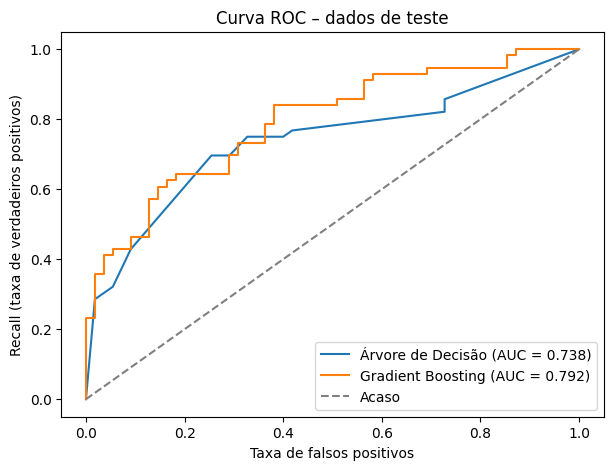

In [8]:
plt.figure(figsize=(7, 5))
for nome, modelo in modelos.items():
    prob = modelo.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, prob)
    auc = metrics.roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray", label="Acaso")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Recall (taxa de verdadeiros positivos)")
plt.title("Curva ROC – dados de teste")
plt.legend()
plt.show()

In [9]:
prob_gb = gb.predict_proba(x_test)[:, 1]  # probabilidade de progressão alta

for limiar in [0.5, 0.3]:
    pred = (prob_gb >= limiar).astype(int)
    print(f"Limiar {limiar}")
    print(pd.DataFrame(metrics.confusion_matrix(y_test, pred),
                       index=["real: baixa", "real: alta"],
                       columns=["previsto: baixa", "previsto: alta"]))
    print(f"acurácia = {metrics.accuracy_score(y_test, pred):.2f} | "
          f"precisão = {metrics.precision_score(y_test, pred):.2f} | "
          f"recall = {metrics.recall_score(y_test, pred):.2f}\n")

Limiar 0.5
             previsto: baixa  previsto: alta
real: baixa               38              17
real: alta                16              40
acurácia = 0.70 | precisão = 0.70 | recall = 0.71

Limiar 0.3
             previsto: baixa  previsto: alta
real: baixa               32              23
real: alta                 9              47
acurácia = 0.71 | precisão = 0.67 | recall = 0.84



In [10]:
explainer = shap.TreeExplainer(gb)
shap_values = explainer(x_test)

In [11]:
importancia = pd.Series(np.abs(shap_values.values).mean(axis=0), index=x_test.columns)
importancia.sort_values(ascending=False).round(3)

,0
triglicerideos,0.806
imc,0.629
hdl,0.438
pressao,0.419
sexo,0.359
idade,0.176
colesterol,0.164
glicose,0.147
ldl,0.058
colesterol_hdl,0.042


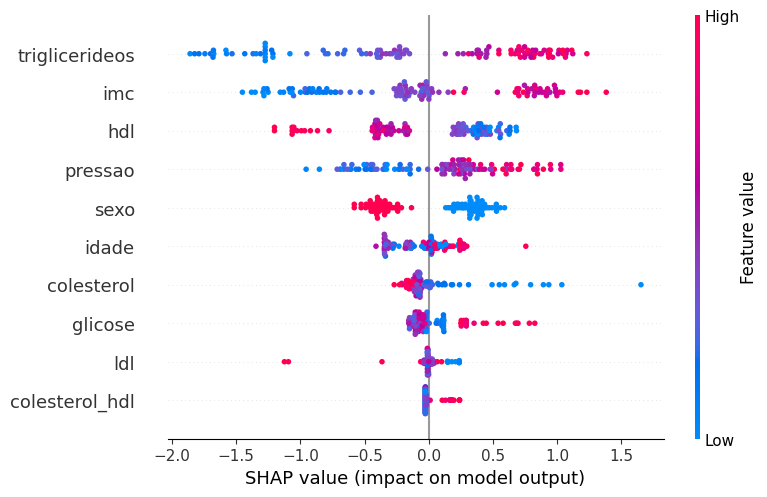

In [12]:
shap.plots.beeswarm(shap_values)

In [13]:
i = np.argmax(prob_gb)
print(f"Probabilidade prevista: {prob_gb[i]:.0%} | classe real: {y_test.iloc[i]}")

paciente = pd.DataFrame({"valor": x_test.iloc[i], "contribuição SHAP": shap_values.values[i].round(3)})
paciente.sort_values("contribuição SHAP", ascending=False)

Probabilidade prevista: 99% | classe real: 1


,valor,contribuição SHAP
triglicerideos,5.7236,0.938
imc,31.2000,0.769
idade,75.0000,0.755
hdl,29.0000,0.680
pressao,117.6700,0.602
sexo,1.0000,0.305
glicose,106.0000,0.292
colesterol_hdl,7.9000,0.180
ldl,138.8000,0.010
colesterol,229.0000,-0.114
